# H08/H10：固定预测诊断与共同训练行对照

2026-10-08 的补充研究。当前研究结论统一维护于 [卷宗](README.md#h10-prediction-diagnostics)。

## 已执行结果

共同训练行固定为102日、507,397行；六次拟合及1,319,910条模型重载预测全部通过核验。
39列减7列的日均 Precision@50 增量如下，单位为百分点：

| 标签 | 原评估17日 | 共同训练行验证27日 | 共同训练行评估17日 |
| --- | ---: | ---: | ---: |
| T+1 | +2.2929 | +0.2978 | +0.7635 |
| T+3 | -2.9412 | +4.3779 | -1.8583 |
| T+5 | -0.7059 | +3.0038 | -1.7647 |

三个期限均未通过预设的两段共同关注条件。原264份模型日名单与新增264份名单均独立复算；
分数带、波动率暴露、替换匹配及逐日稳定性见下文。历史结果已查看，所有区间仅作探索性诊断。
真实新增前向日期为0；未来记录器的10项边界测试通过，完整60日验证尚未开始。

运行前方案：[protocol.json](/home/wsw/app/research-evidence/subscription-prediction-validation-2026-10-08-4ombbzta/protocol.json)。
不搜索模型、期限、K、分组或阈值，不读取生产写凭证，不修改正式输入。
收益回放与实时订阅比较按用户“先完成预测验证”的答复暂缓。


## 1. 冻结输入、源码和环境

精确复跑先复制证据目录到新目录，设置 `SUBSCRIPTION_VALIDATION_EVIDENCE` 指向副本，
并将该副本的 `runtime-source` 放入启动进程的 `PYTHONPATH`。使用项目 Python 3.13 和保存的依赖版本。
不得覆盖本次归档。Notebook 不在运行时改写 import 路径。

In [1]:
from pathlib import Path
from datetime import datetime, time, date
from zoneinfo import ZoneInfo
from dataclasses import asdict
import hashlib
import importlib.metadata
import json
import math
import os
import warnings

import joblib
import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import roc_auc_score, brier_score_loss
from threadpoolctl import threadpool_limits
from IPython.display import display, Image

import src
from src.config.model_config import PreprocessingConfig
from src.training.engines.preprocessing import FittedPreprocessor
from src.training.inference_model import InferenceModel
from src.training.top_selection import select_top_symbols, evaluate_top_selection
from src.utils.datetime_utils import DateTimeUtils

evidence = Path(os.environ.get("SUBSCRIPTION_VALIDATION_EVIDENCE", "/home/wsw/app/research-evidence/subscription-prediction-validation-2026-10-08-4ombbzta"))
assert Path(src.__file__).resolve() == (evidence / "runtime-source/src/__init__.py").resolve()
protocol = json.loads((evidence / "protocol.json").read_text())
assert hashlib.sha256((evidence / "protocol.json").read_bytes()).hexdigest() == "8cb81d713ef2df01f7152339c496308cbd32f2b781bb596e9b93cba086dc7708"
base = evidence / "baseline"
old_protocol = json.loads((base / "protocol.json").read_text())
manifest = json.loads((evidence / "input-manifest.json").read_text())
source_manifest = json.loads((evidence / "source-manifest.json").read_text())
for record in manifest:
    assert hashlib.sha256((evidence / record["path"]).read_bytes()).hexdigest() == record["sha256"], record["path"]
for relative, record in source_manifest.items():
    assert hashlib.sha256((evidence / "runtime-source" / relative).read_bytes()).hexdigest() == record["sha256"], relative
for package, version in json.loads((evidence / "environment.json").read_text())["packages"].items():
    assert importlib.metadata.version(package) == version, package
for folder in ["diagnostics", "common-models", "common-predictions", "figures"]:
    (evidence / folder).mkdir(exist_ok=True)
keys = ["symbol", "trade_date", "decision_ts_utc"]
volatility = "lag_f_d_close_volatility_60d_asof_tminus1_rank"
amount = "lag_f_d_log_amount_rank"
stage_by_date = {day: stage for stage, days in protocol["stages"].items() for day in days}
features = pd.concat([pd.read_parquet(base / f"inputs/fixed/features/previous_day_daily_l2/v1/trade_date={day}/data.parquet")
                      for day in sorted(old_protocol["plans"]["1"]["exit_dates"])], ignore_index=True)
labels = {h: pd.read_parquet(base / f"labels/t{h}.parquet") for h in protocol["horizons"]}
for frame in labels.values():
    assert frame[keys].equals(features[keys])
    assert not frame.duplicated(keys).any()
evaluation_features = features.loc[features.trade_date.isin(protocol["prediction_dates"])].reset_index(drop=True)
assert len(evaluation_features) == 219985
feature_days = {day: group.set_index("symbol") for day, group in evaluation_features.groupby("trade_date", sort=True)}
label_days = {h: {day: group.set_index("symbol") for day, group in frame.groupby("trade_date", sort=True)} for h, frame in labels.items()}
old_metrics = pd.read_parquet(base / "daily-metrics.parquet")
old_selections = pd.read_parquet(base / "selections.parquet")
selection_sets = {(row.horizon, row.trade_date, row.method): set(row.symbols) for row in old_selections.itertuples()}
old_predictions = {(h, method): pd.read_parquet(base / f"predictions/t{h}-{method}.parquet")
                   for h in protocol["horizons"] for method in protocol["features"]}
for prediction in old_predictions.values():
    assert prediction[keys].equals(evaluation_features[keys])
print({"input_files_verified": len(manifest), "source_files_verified": len(source_manifest),
       "feature_rows": len(features), "prediction_rows_per_model": len(evaluation_features)})

{'input_files_verified': 173, 'source_files_verified': 169, 'feature_rows': 753258, 'prediction_rows_per_model': 219985}


## 2. 原名单、极端分数与暴露

逐日从全池分数恢复 Top50，再连接标签恢复命中和有效分母。分数带只用于诊断，主K保持50。
波动率分组使用原P日排名，不利用未来标签形成分组。平均值按日期等权。

In [2]:
band_rows, exposure_rows, score_rows, replacement_rows, overlap_rows = [], [], [], [], []
original_recovered = 0
for horizon in protocol["horizons"]:
    for method in protocol["features"]:
        for day, part in old_predictions[horizon, method].groupby("trade_date", sort=True):
            frame = part.set_index("symbol").join(feature_days[day][[volatility, amount]], validate="one_to_one")
            frame = frame.join(label_days[horizon][day][["y_event", "y_rank_return"]], validate="one_to_one")
            ranked = frame.reset_index().sort_values(["prediction", "symbol"], ascending=[False, True]).reset_index(drop=True)
            chosen = ranked.iloc[:50]
            assert set(chosen.symbol) == selection_sets[horizon, day, method]
            saved = old_metrics.loc[old_metrics.horizon.eq(horizon) & old_metrics.trade_date.eq(day) & old_metrics.method.eq(method)].iloc[0]
            assert chosen.y_event.eq(1).sum() == saved.hits
            assert chosen.y_event.notna().sum() == saved.selected_known
            original_recovered += 1
            ranked["score_band"] = pd.cut(np.arange(1, len(ranked) + 1), protocol["diagnostics"]["score_bands"],
                                           labels=["1-50", "51-100", "101-250", "251-500", "501+"])
            for band, group in ranked.groupby("score_band", observed=True):
                known = group.y_event.notna()
                band_rows.append({"horizon": horizon, "stage": stage_by_date[day], "trade_date": day, "method": method,
                                  "band": str(band), "rows": len(group), "known": int(known.sum()),
                                  "event_rate": group.y_event.mean(), "mean_probability": group.loc[known, "prediction"].mean()})
            exposure_rows.append({"horizon": horizon, "stage": stage_by_date[day], "trade_date": day, "method": method,
                                  "mean_volatility_rank": chosen[volatility].mean(), "high_volatility_share": chosen[volatility].ge(.9).mean(),
                                  "mean_amount_rank": chosen[amount].mean()})
            score_rows.append({"horizon": horizon, "stage": stage_by_date[day], "trade_date": day, "method": method,
                               "pool_rows": len(frame), "known": int(frame.y_event.notna().sum()),
                               "score_q50": frame.prediction.quantile(.5), "score_q90": frame.prediction.quantile(.9),
                               "score_q99": frame.prediction.quantile(.99), "top50_unique_scores": chosen.prediction.nunique()})
    for day in protocol["prediction_dates"]:
        daily = selection_sets[horizon, day, "daily7"]
        full = selection_sets[horizon, day, "all39"]
        outcome = label_days[horizon][day].y_event
        only_daily, only_full = sorted(daily - full), sorted(full - daily)
        assert len(only_daily) == len(only_full)
        replacement_rows.append({"horizon": horizon, "stage": stage_by_date[day], "trade_date": day, "common": len(daily & full),
                                 "replaced": len(only_daily), "daily_only_hits": int(outcome.reindex(only_daily).eq(1).sum()),
                                 "l2_only_hits": int(outcome.reindex(only_full).eq(1).sum()),
                                 "daily_only_known": int(outcome.reindex(only_daily).notna().sum()),
                                 "l2_only_known": int(outcome.reindex(only_full).notna().sum())})
        if horizon > 1:
            joined = pd.concat([label_days[1][day].y_event.rename("t1"), outcome.rename("later")], axis=1).dropna()
            initial, later = joined.t1.eq(1), joined.later.eq(1)
            overlap_rows.append({"horizon": horizon, "stage": stage_by_date[day], "trade_date": day,
                                 "retained_t1_events": int((initial & later).sum()) / int(initial.sum()),
                                 "jaccard": int((initial & later).sum()) / int((initial | later).sum())})
assert original_recovered == 264
bands = pd.DataFrame(band_rows)
exposures = pd.DataFrame(exposure_rows)
scores = pd.DataFrame(score_rows)
replacements = pd.DataFrame(replacement_rows)
event_overlap = pd.DataFrame(overlap_rows)
for name, frame in [("score-bands", bands), ("exposures", exposures), ("pool-scores", scores),
                    ("replacement-counts", replacements), ("event-overlap", event_overlap)]:
    frame.to_csv(evidence / "diagnostics" / f"{name}.csv", index=False)
display(replacements.groupby(["horizon", "stage"])[["replaced", "daily_only_hits", "l2_only_hits"]].sum())
display(bands.loc[bands.band.isin(["1-50", "51-100"])].groupby(["horizon", "stage", "method", "band"])[["event_rate", "mean_probability"]].mean().round(4))

replaced  daily_only_hits  l2_only_hits
horizon stage                                              
1       evaluation       214               64            84
        validation       390              119           133
3       evaluation       366              113            88
        validation       673              124           176
5       evaluation       470              127           121
        validation       841              151           185

event_rate  mean_probability
horizon stage      method band                                
1       evaluation all39  1-50        0.3994            0.3554
                          51-100      0.2968            0.3037
                   daily7 1-50        0.3764            0.3446
                          51-100      0.3035            0.2959
        validation all39  1-50        0.3312            0.3407
                          51-100      0.3002            0.2927
                   daily7 1-50        0.3205            0.3292
                          51-100      0.2652            0.2824
3       evaluation all39  1-50        0.2576            0.2977
                          51-100      0.2651            0.2699
                   daily7 1-50        0.2871            0.2911
                          51-100      0.2358            0.2600
        validation all39  1-50        0.2503            0.2874
                          51-100      0.2417            0.2631
                   daily7 1-50        0.2115            0.2738
                          51-100      0.2055            0.2450
5       evaluation all39  1-50        0.2494            0.2893
                          51-100      0.2366            0.2632
                   daily7 1-50        0.2565            0.2725
                          51-100      0.2376            0.2485
        validation all39  1-50        0.2117            0.2792
                          51-100      0.2208            0.2570
                   daily7 1-50        0.1859            0.2569
                          51-100      0.1667            0.2336

## 3. 在预测时已知变量上匹配替换名单

每个日期、期限内，对L2换入与日频换出名单进行一对一匹配。变量是日频分数的全池百分位、
原波动率排名、原成交额排名；三个caliper分别为0.05、0.10、0.10。先最大化满足边界的配对数，
再最小化标准化距离。配对不读取结果；配完后才连接标签。未知特征、无法匹配和未知结果分别报告。
匹配子集的变化属于条件性描述，不能外推到未匹配位置，也不识别因果。

In [3]:
matched_rows, matching_days = [], []
calipers = np.asarray(protocol["diagnostics"]["replacement_matching"]["calipers"])
for horizon in protocol["horizons"]:
    daily_prediction_days = {day: frame.set_index("symbol").prediction for day, frame in old_predictions[horizon, "daily7"].groupby("trade_date")}
    for day in protocol["prediction_dates"]:
        daily_set, full_set = selection_sets[horizon, day, "daily7"], selection_sets[horizon, day, "all39"]
        control = sorted(daily_set - full_set)
        candidate = sorted(full_set - daily_set)
        covariates = feature_days[day][[volatility, amount]].copy()
        covariates.insert(0, "daily_score_rank", daily_prediction_days[day].rank(method="average", pct=True))
        controls = covariates.reindex(control).dropna()
        candidates = covariates.reindex(candidate).dropna()
        matched_count = 0
        known_pairs = 0
        differences = []
        if len(controls) and len(candidates):
            distances = np.abs(candidates.to_numpy()[:, None, :] - controls.to_numpy()[None, :, :])
            feasible = (distances <= calipers).all(axis=2)
            costs = np.where(feasible, (distances / calipers).sum(axis=2), 1_000_000.0)
            row_indices, col_indices = linear_sum_assignment(costs)
            assignments = [(int(i), int(j)) for i, j in zip(row_indices, col_indices) if feasible[i, j]]
            assert len({i for i, _ in assignments}) == len(assignments)
            assert len({j for _, j in assignments}) == len(assignments)
            for i, j in assignments:
                candidate_symbol, control_symbol = candidates.index[i], controls.index[j]
                assert (distances[i, j] <= calipers).all()
                candidate_outcome = label_days[horizon][day].y_event.loc[candidate_symbol]
                control_outcome = label_days[horizon][day].y_event.loc[control_symbol]
                pair_known = pd.notna(candidate_outcome) and pd.notna(control_outcome)
                matched_count += 1
                known_pairs += int(pair_known)
                if pair_known:
                    differences.append(float(candidate_outcome - control_outcome))
                matched_rows.append({"horizon": horizon, "stage": stage_by_date[day], "trade_date": day,
                                     "candidate_symbol": candidate_symbol, "control_symbol": control_symbol,
                                     "candidate_event": candidate_outcome, "control_event": control_outcome,
                                     "pair_known": pair_known, "score_rank_distance": distances[i, j, 0],
                                     "volatility_distance": distances[i, j, 1], "amount_distance": distances[i, j, 2]})
        matching_days.append({"horizon": horizon, "stage": stage_by_date[day], "trade_date": day,
                              "replaced": len(control), "matched": matched_count, "known_pairs": known_pairs,
                              "control_missing_covariates": len(control) - len(controls),
                              "candidate_missing_covariates": len(candidate) - len(candidates),
                              "unmatched": len(control) - matched_count,
                              "matched_mean_difference": float(np.mean(differences)) if differences else np.nan})
matched = pd.DataFrame(matched_rows)
matching = pd.DataFrame(matching_days)
assert (matching.matched + matching.unmatched).equals(matching.replaced)
assert matching.known_pairs.le(matching.matched).all()
matched.to_csv(evidence / "diagnostics/matched-pairs.csv", index=False)
matching.to_csv(evidence / "diagnostics/matching-daily.csv", index=False)
matched_summary = matching.groupby(["horizon", "stage"]).agg(
    replaced=("replaced", "sum"), matched=("matched", "sum"), known_pairs=("known_pairs", "sum"),
    matched_days=("matched_mean_difference", "count"), mean_difference=("matched_mean_difference", "mean"),
    control_missing_covariates=("control_missing_covariates", "sum"), candidate_missing_covariates=("candidate_missing_covariates", "sum"),
).reset_index()
matched_summary["coverage"] = matched_summary.matched / matched_summary.replaced
matched_summary.to_csv(evidence / "diagnostics/matching-summary.csv", index=False)
display(matched_summary.round(4))

,horizon,stage,replaced,matched,known_pairs,matched_days,mean_difference,control_missing_covariates,candidate_missing_covariates,coverage
0,1,evaluation,214,143,143,17,-0.0173,7,5,0.6682
1,1,validation,390,282,282,27,0.0206,9,10,0.7231
2,3,evaluation,366,291,291,17,-0.0743,6,2,0.7951
3,3,validation,673,509,508,27,0.0221,9,2,0.7563
4,5,evaluation,470,422,422,17,-0.0166,3,0,0.8979
5,5,validation,841,667,665,27,0.0252,10,1,0.7931


## 4. 时间稳定性、重复入选和波动率分层

逐日差值、逐日删除一个日期后的均值范围及相邻名单重合用于显示敏感性，不删日重算主结论。
股票日不作为独立市场日期；高波动层的高事件率不等于可执行收益。

In [4]:
stability_rows, concentration_rows, volatility_rows = [], [], []
for horizon in protocol["horizons"]:
    for stage, dates in protocol["stages"].items():
        pair = old_metrics.loc[old_metrics.horizon.eq(horizon) & old_metrics.stage.eq(stage) & old_metrics.method.isin(protocol["features"])].pivot(index="trade_date", columns="method", values="precision")
        delta = (pair.all39 - pair.daily7).to_numpy()
        loo = (delta.sum() - delta) / (len(delta) - 1)
        stability_rows.append({"horizon": horizon, "stage": stage, "mean_difference": delta.mean(), "daily_sd": delta.std(ddof=1),
                               "loo_min": loo.min(), "loo_max": loo.max(), "wins": int((delta > 0).sum()),
                               "ties": int((delta == 0).sum()), "losses": int((delta < 0).sum())})
        for method in protocol["features"]:
            lists = [selection_sets[horizon, day, method] for day in dates]
            occurrences = pd.Series([symbol for selected in lists for symbol in selected]).value_counts()
            concentration_rows.append({"horizon": horizon, "stage": stage, "method": method,
                                       "unique_symbols": len(occurrences), "positions": int(occurrences.sum()),
                                       "top10_symbol_share": occurrences.iloc[:10].sum() / occurrences.sum(),
                                       "mean_consecutive_overlap": np.mean([len(a & b) / 50 for a, b in zip(lists[:-1], lists[1:])])})
        for day in dates:
            frame = feature_days[day][[volatility]].join(label_days[horizon][day][["y_event"]], validate="one_to_one")
            frame["volatility_group"] = pd.cut(frame[volatility], protocol["diagnostics"]["volatility_boundaries"], include_lowest=True, labels=[1,2,3,4,5])
            for group, part in frame.groupby("volatility_group", observed=True):
                volatility_rows.append({"horizon": horizon, "stage": stage, "trade_date": day, "group": int(group),
                                        "rows": len(part), "known": int(part.y_event.notna().sum()), "event_rate": part.y_event.mean()})
stability, concentration, volatility_groups = pd.DataFrame(stability_rows), pd.DataFrame(concentration_rows), pd.DataFrame(volatility_rows)
for name, frame in [("stability", stability), ("concentration", concentration), ("volatility-groups", volatility_groups)]:
    frame.to_csv(evidence / "diagnostics" / f"{name}.csv", index=False)
display(stability.round(4))
display(concentration.round(4))

,horizon,stage,mean_difference,daily_sd,loo_min,loo_max,wins,ties,losses
0,1,validation,0.0108,0.0425,0.0066,0.0127,12,5,10
1,1,evaluation,0.0229,0.0473,0.0169,0.0282,9,3,5
2,3,validation,0.0388,0.0995,0.0311,0.0449,15,1,11
3,3,evaluation,-0.0294,0.0819,-0.0388,-0.0188,5,2,10
4,5,validation,0.0258,0.0907,0.0176,0.0314,15,2,10
5,5,evaluation,-0.0071,0.0628,-0.0137,-0.0013,6,2,9


,horizon,stage,method,unique_symbols,positions,top10_symbol_share,mean_consecutive_overlap
0,1,validation,daily7,580,1350,0.0807,0.3138
1,1,validation,all39,568,1350,0.0756,0.3338
2,1,evaluation,daily7,392,850,0.0882,0.3325
3,1,evaluation,all39,365,850,0.0918,0.3750
4,3,validation,daily7,549,1350,0.0963,0.3285
5,3,validation,all39,401,1350,0.1163,0.3969
6,3,evaluation,daily7,325,850,0.1153,0.3875
7,3,evaluation,all39,295,850,0.1482,0.4775
8,5,validation,daily7,473,1350,0.1059,0.4323
9,5,validation,all39,322,1350,0.1481,0.5469


## 5. 统一训练行和标签成熟时间

三个期限统一使用02-03至07-09的102日。只在拟合区间内求三个已成熟标签的已知交集，
用于控制训练行差异；未来预测池保持原219,985行。交集本身改变训练样本，不能把本对照当成
原模型的精确恢复或把结果升级为确认。

In [5]:
date_mask = features.trade_date.isin(protocol["common_train_dates"])
common_mask = date_mask.copy()
for horizon in protocol["horizons"]:
    common_mask &= labels[horizon].y_event.notna()
first_decision = DateTimeUtils.local_time_to_utc_epoch_us(time(9), date(2026, 7, 17))
for horizon in protocol["horizons"]:
    assert labels[horizon].loc[common_mask, "label_ready_ts"].lt(first_decision).all()
    altered = labels[horizon].y_event.copy()
    altered.loc[features.trade_date.isin(protocol["prediction_dates"])] = np.nan
    np.testing.assert_array_equal(altered.loc[common_mask], labels[horizon].loc[common_mask, "y_event"])
altered_common = date_mask.copy()
for horizon in protocol["horizons"]:
    altered = labels[horizon].y_event.copy()
    altered.loc[features.trade_date.isin(protocol["prediction_dates"])] = 1 - altered.loc[features.trade_date.isin(protocol["prediction_dates"])]
    altered_common &= altered.notna()
np.testing.assert_array_equal(common_mask, altered_common)
fit_keys = features.loc[common_mask, keys].reset_index(drop=True)
assert fit_keys.trade_date.nunique() == 102
counts = fit_keys.groupby("trade_date").symbol.transform("size").to_numpy(dtype=float)
weights = 1.0 / counts
weights = weights / weights.mean()
date_weight = pd.Series(weights).groupby(fit_keys.trade_date).sum()
np.testing.assert_allclose(date_weight, date_weight.iloc[0], rtol=1e-14, atol=0)
fit_table = fit_keys.copy()
fit_table["weight"] = weights
for horizon in protocol["horizons"]:
    fit_table[f"y_t{horizon}"] = labels[horizon].loc[common_mask, "y_event"].to_numpy()
fit_table.to_parquet(evidence / "common-models/fit-keys.parquet", index=False)
fit_key_hash = hashlib.sha256(pd.util.hash_pandas_object(fit_keys, index=True).to_numpy().tobytes()).hexdigest()
print({"common_fit_rows": len(fit_keys), "common_fit_days": fit_keys.trade_date.nunique(),
       "dropped_unknown_any_horizon": int(date_mask.sum() - common_mask.sum()), "last_fit_date": fit_keys.trade_date.max(), "key_hash": fit_key_hash})

{'common_fit_rows': 507397, 'common_fit_days': 102, 'dropped_unknown_any_horizon': 950, 'last_fit_date': '2026-07-09', 'key_hash': '1e7e8ef798e297f6e0931af4c14c11533dc42d4416834507b5e7f9e5ebc53c04'}


## 6. 六次固定拟合

沿用原模型、填0.5、不缩放、日期等权及随机种子。不早停，不在验证后重拟合，不根据结果选择期限。
保存每个新模型及全池预测；原H08前向确认仍使用原两个模型，不替换为本轮共同训练行模型。

In [6]:
common_predictions, fit_records = {}, []
for horizon in protocol["horizons"]:
    target = fit_table[f"y_t{horizon}"].to_numpy(dtype=float)
    for method, columns in protocol["features"].items():
        train_X = features.loc[common_mask, columns].reset_index(drop=True)
        preprocess = FittedPreprocessor.fit(train_X=train_X, config=PreprocessingConfig.model_validate(protocol["preprocessing"]))
        kept, X = preprocess.transform(train_X.to_numpy(dtype=float))
        assert kept.all()
        np.testing.assert_array_equal(X, train_X.fillna(.5).to_numpy(dtype=float))
        estimator = HistGradientBoostingClassifier(**protocol["model_params"])
        with threadpool_limits(limits=1), warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            estimator.fit(X, target, sample_weight=weights)
        assert estimator.n_iter_ == 100
        fitted = InferenceModel(model=estimator, preprocess=preprocess, feature_set="previous_day_daily_l2", feature_version="v1",
                                train_dates=tuple(protocol["common_train_dates"]), label_set=f"research_common_endpoint_high_t{horizon}",
                                label_version="draft", label_column="y_event", prediction_method="positive_probability")
        model_path = evidence / f"common-models/t{horizon}-{method}.joblib"
        joblib.dump(fitted, model_path)
        with threadpool_limits(limits=1):
            predictions = fitted.predict(evaluation_features[columns].to_numpy(dtype=float))
        assert np.isfinite(predictions).all() and ((predictions >= 0) & (predictions <= 1)).all()
        saved = evaluation_features[keys].copy()
        saved["prediction"] = predictions
        saved["stage"] = saved.trade_date.map(stage_by_date)
        saved.to_parquet(evidence / f"common-predictions/t{horizon}-{method}.parquet", index=False)
        common_predictions[horizon, method] = saved
        fit_records.append({"horizon": horizon, "method": method, "train_days": 102, "fit_rows": len(fit_keys), "fit_key_sha256": fit_key_hash,
                            "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(), "prediction_rows": len(saved)})
        (evidence / "common-models/fit-records.json").write_text(json.dumps(fit_records, indent=2))
        print(f"Fitted T+{horizon} {method}: {len(fit_keys):,} identical rows; {len(saved):,} predictions.", flush=True)
assert len(fit_records) == 6

Fitted T+1 daily7: 507,397 identical rows; 219,985 predictions.
Fitted T+1 all39: 507,397 identical rows; 219,985 predictions.
Fitted T+3 daily7: 507,397 identical rows; 219,985 predictions.
Fitted T+3 all39: 507,397 identical rows; 219,985 predictions.
Fitted T+5 daily7: 507,397 identical rows; 219,985 predictions.
Fitted T+5 all39: 507,397 identical rows; 219,985 predictions.


## 7. 评价和配对区间

先锁定全池名单，后评价有效标签。独立NumPy排序核验每份名单和分子分母。
两段分别使用原5日区块；事先固定的10日区块仅作敏感性诊断，不取有利区间替换主结果。

In [7]:
common_metric_rows, common_selection_rows = [], []
for (horizon, method), prediction in common_predictions.items():
    for day, group in prediction.groupby("trade_date", sort=True):
        label = label_days[horizon][day].reindex(group.symbol)
        symbols = group.symbol.to_numpy(dtype=str)
        values = group.prediction.to_numpy(dtype=float)
        positions = select_top_symbols(symbols, values, top_k=50)
        independent = np.lexsort((symbols, -values))[:50]
        np.testing.assert_array_equal(positions, independent)
        metrics = asdict(evaluate_top_selection(ranks=label.y_rank_return.to_numpy(dtype=float), selected=positions))
        picked = label.iloc[independent]
        assert metrics["hits"] == picked.y_event.eq(1).sum()
        assert metrics["selected_known"] == picked.y_event.notna().sum()
        assert metrics["precision"] == picked.y_event.mean()
        known = label.y_event.notna().to_numpy()
        common_metric_rows.append({"horizon": horizon, "method": method, "stage": stage_by_date[day], "trade_date": day,
                                   **metrics, "auc": roc_auc_score(label.y_event.to_numpy()[known], values[known]),
                                   "brier": brier_score_loss(label.y_event.to_numpy()[known], values[known])})
        common_selection_rows.append({"horizon": horizon, "method": method, "stage": stage_by_date[day], "trade_date": day,
                                      "symbols": symbols[positions].tolist()})
common_metrics = pd.DataFrame(common_metric_rows)
common_selections = pd.DataFrame(common_selection_rows)
assert len(common_metrics) == 264
common_metrics.to_parquet(evidence / "common-metrics.parquet", index=False)
common_selections.to_parquet(evidence / "common-selections.parquet", index=False)
summary = common_metrics.groupby(["horizon", "stage", "method"]).agg(days=("trade_date", "size"), precision=("precision", "mean"),
    hits=("hits", "sum"), known=("selected_known", "sum"), coverage=("selection_coverage", "mean"), auc=("auc", "mean"), brier=("brier", "mean")).reset_index()
summary.to_csv(evidence / "common-summary.csv", index=False)
comparisons = []
for scope, metrics in [("original", old_metrics), ("common_rows", common_metrics)]:
    paired = metrics.loc[metrics.method.isin(protocol["features"])].pivot(index=["horizon", "stage", "trade_date"], columns="method", values="precision")
    paired["difference"] = paired.all39 - paired.daily7
    paired.to_csv(evidence / f"{scope}-paired-daily.csv")
    for horizon in protocol["horizons"]:
        for stage in protocol["stages"]:
            values = paired.xs((horizon, stage)).difference.to_numpy()
            for block in [5, 10]:
                rng = np.random.default_rng(protocol["uncertainty"]["seed"])
                starts = rng.integers(0, len(values), size=(20000, math.ceil(len(values) / block)))
                indices = ((starts[..., None] + np.arange(block)) % len(values)).reshape(20000, -1)[:, :len(values)]
                means = values[indices].mean(axis=1)
                lower, upper = np.quantile(means, [.025, .975])
                one_sided = float(np.quantile(means, .05))
                comparisons.append({"scope": scope, "horizon": horizon, "stage": stage, "block_sessions": block,
                                    "mean_difference": values.mean(), "ci95_lower": lower, "ci95_upper": upper,
                                    "one_sided95_lower": one_sided, "criterion_met": bool(values.mean() >= .02 and one_sided > 0)})
comparison = pd.DataFrame(comparisons)
comparison.to_csv(evidence / "paired-comparison.csv", index=False)
original_check = comparison.loc[comparison.scope.eq("original") & comparison.block_sessions.eq(5)].set_index(["horizon", "stage"]).sort_index()
archived_check = pd.read_csv(base / "paired-comparison.csv").set_index(["horizon", "stage"]).sort_index()
np.testing.assert_allclose(original_check[["mean_difference", "ci95_lower", "ci95_upper", "one_sided95_lower"]], archived_check[["mean_difference", "ci95_lower", "ci95_upper", "one_sided95_lower"]], rtol=1e-12, atol=1e-15)
display(summary.round(4))
display(comparison.loc[comparison.scope.eq("common_rows") & comparison.block_sessions.eq(5)].round(4))

,horizon,stage,method,days,precision,hits,known,coverage,auc,brier
0,1,evaluation,all39,17,0.3876,329,849,0.9988,0.7248,0.0836
1,1,evaluation,daily7,17,0.3799,322,848,0.9976,0.7186,0.0840
2,1,validation,all39,27,0.3227,435,1348,0.9985,0.7194,0.0839
3,1,validation,daily7,27,0.3197,431,1348,0.9985,0.7123,0.0845
4,3,evaluation,all39,17,0.2661,226,849,0.9988,0.6850,0.0859
5,3,evaluation,daily7,17,0.2847,242,850,1.0000,0.6803,0.0861
6,3,validation,all39,27,0.2634,355,1349,0.9993,0.6704,0.0863
7,3,validation,daily7,27,0.2197,296,1349,0.9993,0.6630,0.0867
8,5,evaluation,all39,17,0.2424,206,850,1.0000,0.6785,0.0861
9,5,evaluation,daily7,17,0.2600,221,850,1.0000,0.6729,0.0864


,scope,horizon,stage,block_sessions,mean_difference,ci95_lower,ci95_upper,one_sided95_lower,criterion_met
12,common_rows,1,validation,5,0.0030,-0.0163,0.0237,-0.0133,False
14,common_rows,1,evaluation,5,0.0076,-0.0088,0.0247,-0.0065,False
16,common_rows,3,validation,5,0.0438,-0.0030,0.0920,0.0038,True
18,common_rows,3,evaluation,5,-0.0186,-0.0421,0.0094,-0.0393,False
20,common_rows,5,validation,5,0.0300,-0.0026,0.0645,0.0022,True
22,common_rows,5,evaluation,5,-0.0176,-0.0400,0.0082,-0.0376,False


## 8. 结果图

第一图展示原模型逐日增量和共同训练行的区间；第二图展示各分数带的概率与实际事件率。
区间均为历史探索性名义区间，不能替代60日真实前向验证。

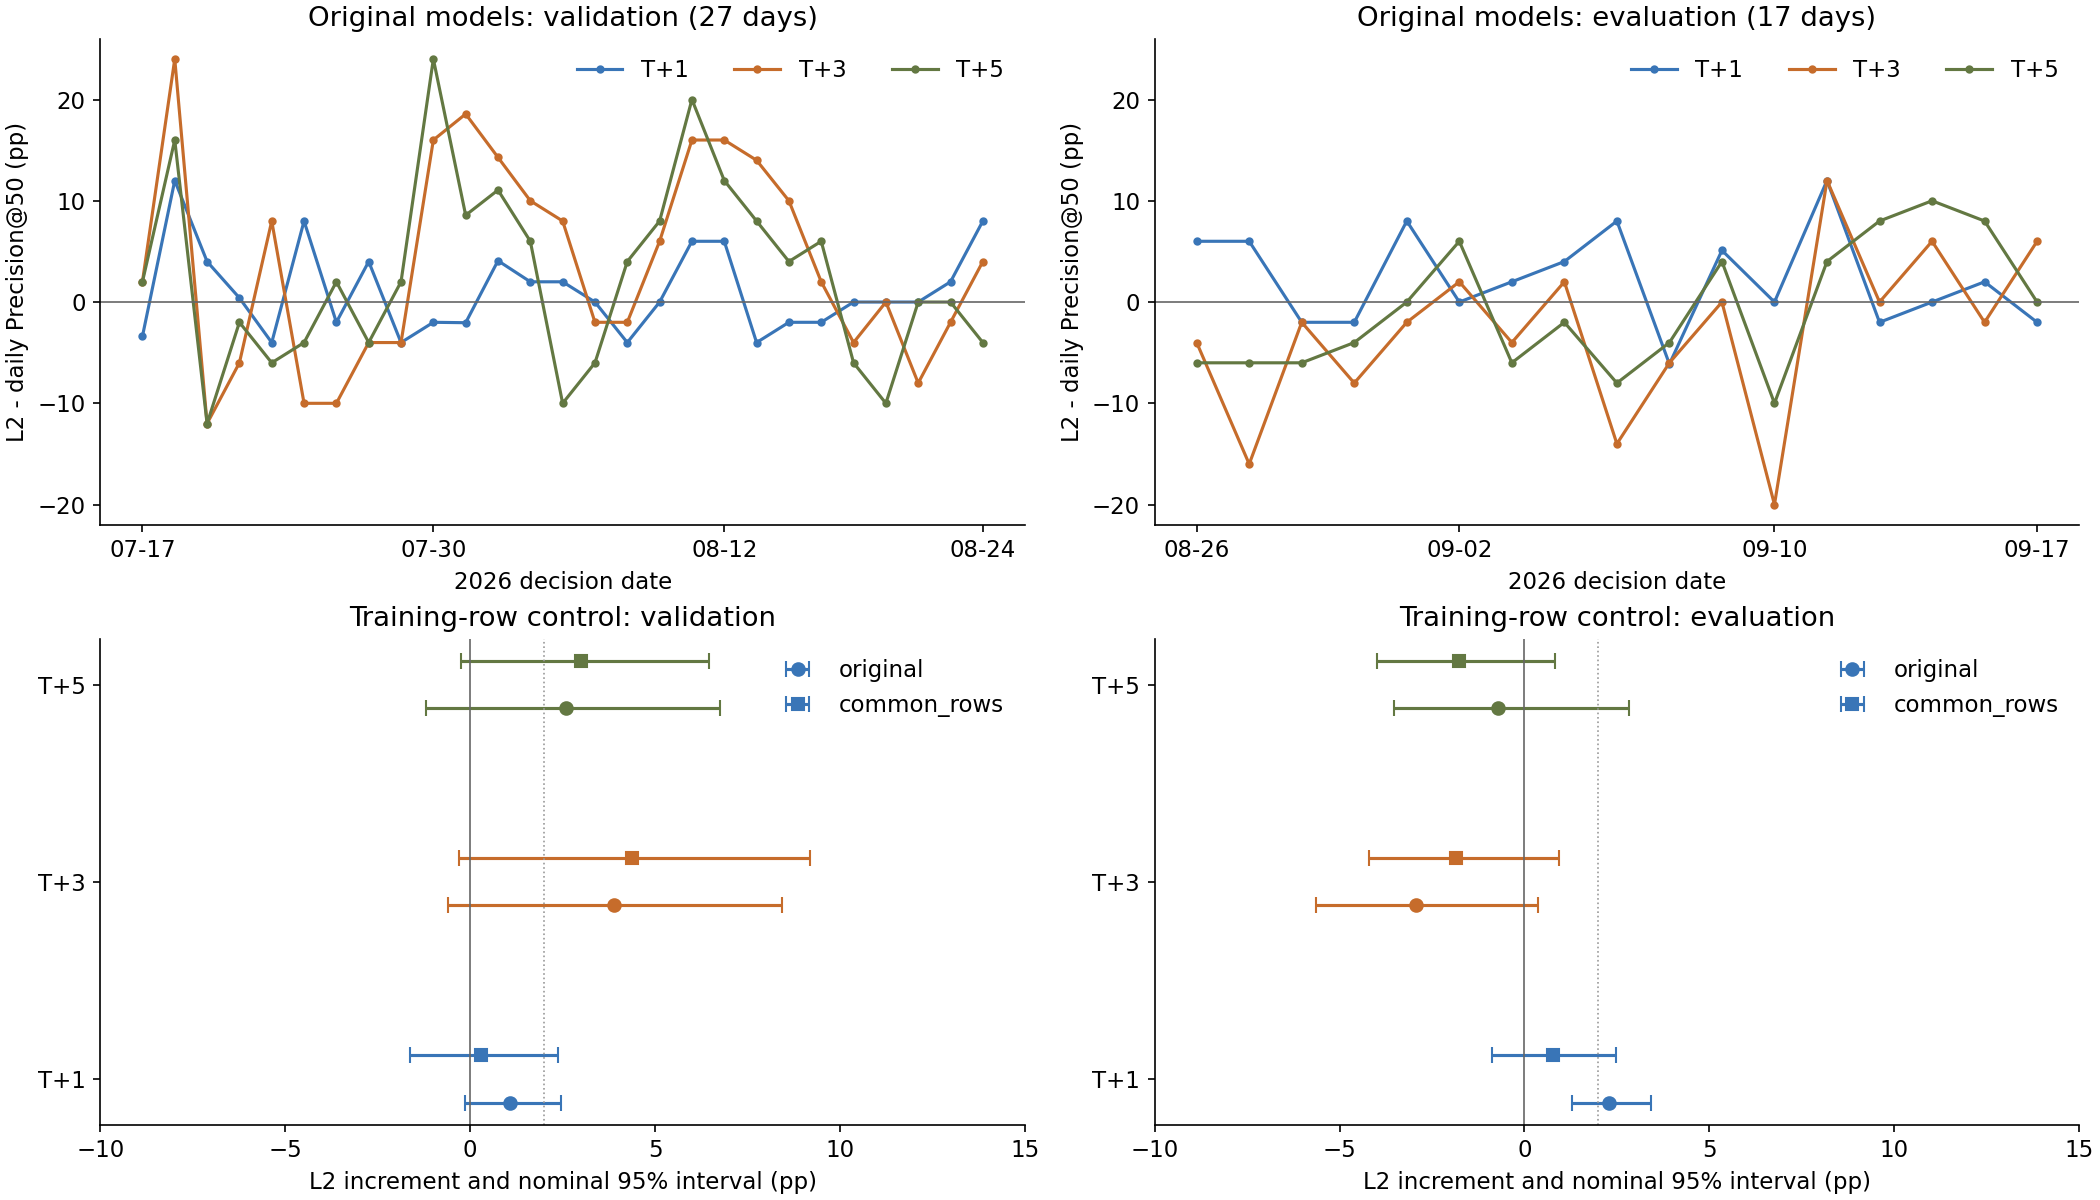

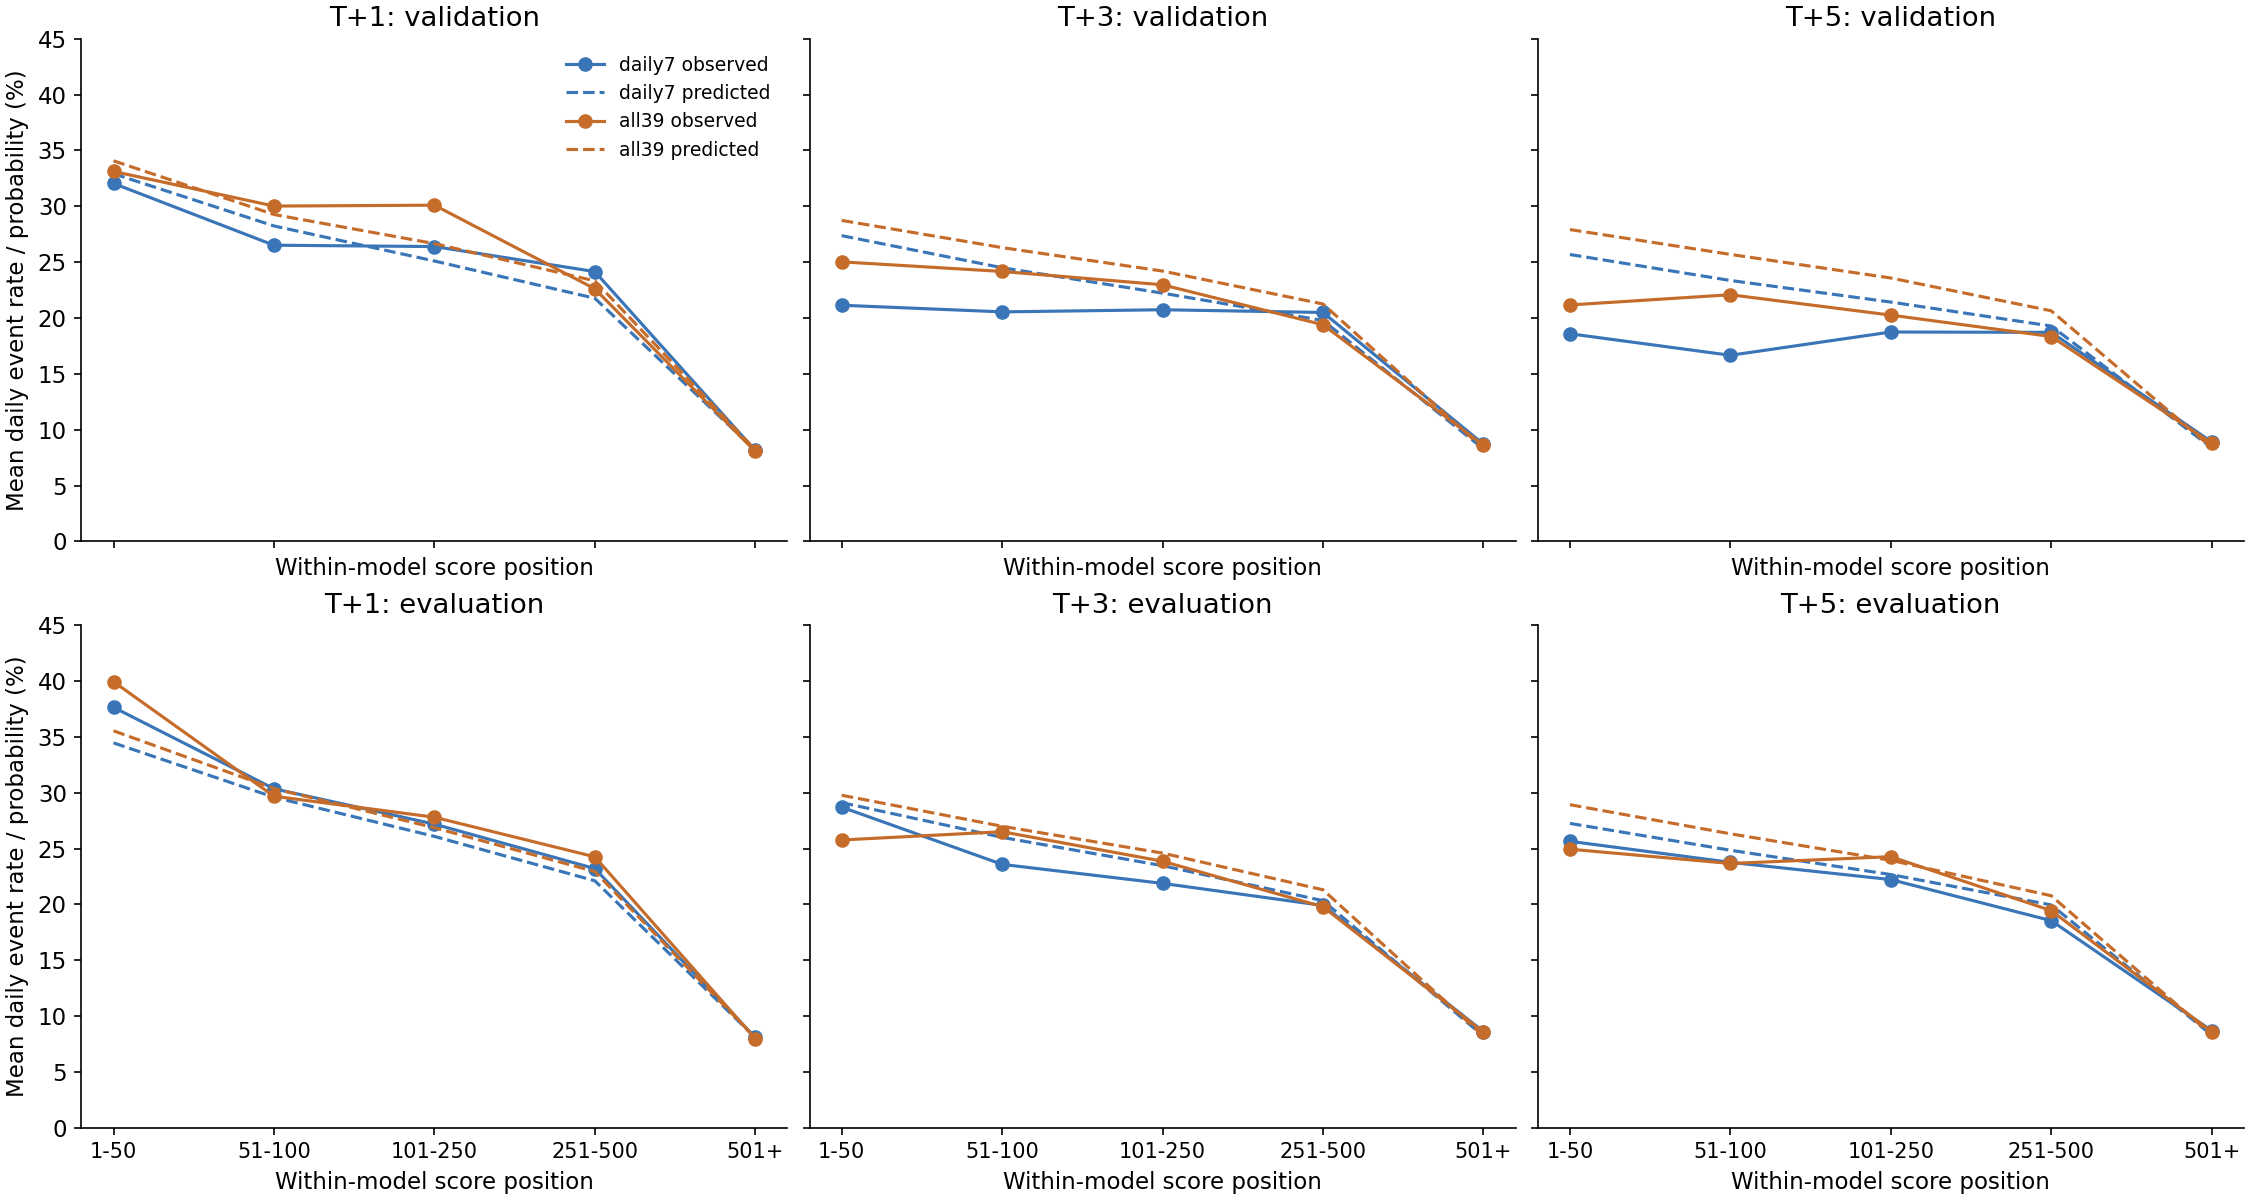

In [8]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
colors = {1: "#3975B7", 3: "#C66C2B", 5: "#637842"}
fig, axes = plt.subplots(2, 2, figsize=(14, 8), layout="constrained")
for column, (stage, dates) in enumerate(protocol["stages"].items()):
    ax = axes[0, column]
    for horizon in protocol["horizons"]:
        pair = old_metrics.loc[old_metrics.horizon.eq(horizon) & old_metrics.stage.eq(stage) & old_metrics.method.isin(protocol["features"])].pivot(index="trade_date", columns="method", values="precision").reindex(dates)
        ax.plot(np.arange(len(dates)), (pair.all39 - pair.daily7) * 100, label=f"T+{horizon}", color=colors[horizon], marker="o", markersize=3)
    ax.axhline(0, color="#666666", linewidth=.8)
    ax.set_ylim(-22, 26)
    ticks = sorted(set([0, len(dates)//3, 2*len(dates)//3, len(dates)-1]))
    ax.set_xticks(ticks, [dates[i][5:] for i in ticks])
    ax.set(title=f"Original models: {stage} ({len(dates)} days)", xlabel="2026 decision date", ylabel="L2 - daily Precision@50 (pp)")
    ax.legend(ncol=3, frameon=False)
    ax = axes[1, column]
    for j, horizon in enumerate(protocol["horizons"]):
        for offset, scope, marker in [(-.12, "original", "o"), (.12, "common_rows", "s")]:
            row = comparison.loc[comparison.scope.eq(scope) & comparison.horizon.eq(horizon) & comparison.stage.eq(stage) & comparison.block_sessions.eq(5)].iloc[0]
            ax.errorbar(row.mean_difference * 100, j + offset, xerr=[[100*(row.mean_difference-row.ci95_lower)], [100*(row.ci95_upper-row.mean_difference)]],
                        fmt=marker, color=colors[horizon], capsize=4, label=scope if horizon==1 else None)
    ax.axvline(0, color="#666666", linewidth=.8)
    ax.axvline(2, color="#999999", linewidth=.8, linestyle=":")
    ax.set_yticks([0,1,2], ["T+1", "T+3", "T+5"])
    ax.set_xlim(-10, 15)
    ax.set(title=f"Training-row control: {stage}", xlabel="L2 increment and nominal 95% interval (pp)")
    ax.legend(frameon=False)
fig.savefig(evidence / "figures/increment-and-training-control.png", dpi=150)
plt.close(fig)
display(Image(filename=str(evidence / "figures/increment-and-training-control.png")))
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True, layout="constrained")
order = ["1-50", "51-100", "101-250", "251-500", "501+"]
for row, stage in enumerate(protocol["stages"]):
    for column, horizon in enumerate(protocol["horizons"]):
        ax = axes[row, column]
        for method, color in [("daily7", "#3975B7"), ("all39", "#C66C2B")]:
            stats = bands.loc[bands.horizon.eq(horizon) & bands.stage.eq(stage) & bands.method.eq(method)].groupby("band")[["event_rate", "mean_probability"]].mean().reindex(order)
            ax.plot(order, 100*stats.event_rate, color=color, marker="o", label=f"{method} observed")
            ax.plot(order, 100*stats.mean_probability, color=color, linestyle="--", label=f"{method} predicted")
        ax.set(title=f"T+{horizon}: {stage}", xlabel="Within-model score position")
        ax.set_ylim(0, 45)
        ax.tick_params(axis="x", labelsize=10)
        if column==0:ax.set_ylabel("Mean daily event rate / probability (%)")
        if row==0 and column==0:ax.legend(frameon=False, fontsize=9)
fig.savefig(evidence / "figures/score-band-diagnostics.png", dpi=150)
plt.close(fig)
display(Image(filename=str(evidence / "figures/score-band-diagnostics.png")))

## 9. 前向记录就绪核查

只检查已知本地正式存储、研究证据根及原方案；不从文件mtime推断历史接收时间。
首日缺少可验证的决策前记录，就不能算作严格确认。未来新窗口须在采集就绪且尚未查看效果时冻结；
本单元不安装调度，也不把演练和事后推理登记为有效预测。

In [9]:
storage = Path("/home/wsw/app/data")
calendar = pd.read_parquet(base / "inputs/fixed/processed/trade_calendar/v1/year=2026/data.parquet")
sessions = sorted(calendar.loc[calendar.is_open, "trade_date"].tolist())
now = datetime.now(ZoneInfo("Asia/Shanghai"))
original_first = "2026-10-08"
previous = sessions[sessions.index(original_first)-1]
readiness = []
for area, dataset in [("features", "previous_day_daily_l2"), ("processed", "previous_day_eligibility"),
                       ("features", "l2_stock_1430"), ("features", "tushare_daily_basic"),
                       ("processed", "stock_basic"), ("processed", "stock_st"), ("processed", "suspend_d")]:
    root = storage / area / dataset / "v1"
    dates = sorted(path.name.removeprefix("trade_date=") for path in root.glob("trade_date=*") if path.is_dir())
    needed = original_first if dataset in ["previous_day_daily_l2", "previous_day_eligibility"] else previous
    readiness.append({"area": area, "dataset": dataset, "required_date_for_original_first_day": needed,
                      "partition_present": (root / f"trade_date={needed}/meta.json").exists(), "latest_partition": dates[-1] if dates else None})
possible_forward_roots = sorted(path.name for path in evidence.parent.iterdir() if path.is_dir() and any(term in path.name for term in ["forward", "confirmation"]))
possible_forward_experiments = sorted(path.name for path in (storage / "experiments").iterdir() if path.is_dir() and any(term in path.name for term in ["forward", "confirmation", "2026-10-08"]))
future_dates = [day for day in sessions if day > now.date().isoformat()]
future_candidate = future_dates[:60]
audit = {"observed_at": now.isoformat(), "checked_roots": [str(storage), str(evidence.parent)],
         "original_start": original_first, "original_decision_deadline_passed": now > datetime(2026,10,8,9,tzinfo=ZoneInfo("Asia/Shanghai")),
         "partition_readiness": readiness, "possible_forward_roots": possible_forward_roots,
         "possible_forward_experiments": possible_forward_experiments,
         "actual_predecision_receipt_found_in_checked_roots": False,
         "strict_confirmation_started": False, "new_independent_dates": 0,
         "next_60_calendar_sessions_candidate_only": future_candidate,
         "candidate_last_label_next_session_in_calendar": len(future_candidate)==60 and sessions.index(future_candidate[-1])+1 < len(sessions),
         "calendar_2027_present": (storage / "processed/trade_calendar/v1/year=2027/meta.json").exists(),
         "limitations": ["No record found in known roots is not a claim about every other machine or account.",
                         "File timestamps and historical assumed availability are not received_at evidence.",
                         "Candidate date list is not an activated or newly frozen study.",
                         "No supported Codex local automation tool was exposed in this session; no scheduler installed."],
         "next_trigger": "Isolated recorder verified; required previous-session inputs captured before decision; full 60-date calendar and terminal next-session maturity identified. Freeze the then-future window before viewing any outcomes."}
(evidence / "forward-readiness.json").write_text(json.dumps(audit, ensure_ascii=False, indent=2))
display(pd.DataFrame(readiness))
print({"original_start_recoverable_as_strict": False, "candidate_calendar_days": len(future_candidate),
       "candidate_first": future_candidate[0] if future_candidate else None, "candidate_last": future_candidate[-1] if future_candidate else None,
       "terminal_maturity_known": audit["candidate_last_label_next_session_in_calendar"]})

{'original_start_recoverable_as_strict': False, 'candidate_calendar_days': 60, 'candidate_first': '2026-10-09', 'candidate_last': '2026-12-31', 'terminal_maturity_known': False}


,area,dataset,required_date_for_original_first_day,partition_present,latest_partition
0,features,previous_day_daily_l2,2026-10-08,False,2026-09-17
1,processed,previous_day_eligibility,2026-10-08,False,2026-09-17
2,features,l2_stock_1430,2026-09-30,True,2026-09-30
3,features,tushare_daily_basic,2026-09-30,False,2026-09-18
4,processed,stock_basic,2026-09-30,True,2026-09-30
5,processed,stock_st,2026-09-30,True,2026-09-30
6,processed,suspend_d,2026-09-30,True,2026-09-30


## 10. 重载与证据守恒

重载六模型逐值恢复新预测。检查原输入、冻结源码、相同训练行及已消费日期边界。
这些验收表示本轮实验可复算，不表示模型已采用、前向确认完成或可以实盘交易。

In [10]:
reloaded_rows = 0
for record in fit_records:
    horizon, method = record["horizon"], record["method"]
    path = evidence / f"common-models/t{horizon}-{method}.joblib"
    assert hashlib.sha256(path.read_bytes()).hexdigest() == record["model_sha256"]
    restored = joblib.load(path)
    with threadpool_limits(limits=1):
        actual = restored.predict(evaluation_features[protocol["features"][method]].to_numpy(dtype=float))
    saved = common_predictions[horizon, method]
    np.testing.assert_array_equal(actual, saved.prediction)
    assert saved[keys].equals(evaluation_features[keys])
    reloaded_rows += len(actual)
for record in manifest:
    assert hashlib.sha256((evidence / record["path"]).read_bytes()).hexdigest() == record["sha256"]
for relative, record in source_manifest.items():
    assert hashlib.sha256((evidence / "runtime-source" / relative).read_bytes()).hexdigest() == record["sha256"]
verification = {"protocol_sha256": hashlib.sha256((evidence / "protocol.json").read_bytes()).hexdigest(),
                "source_commit": protocol["base_commit"], "input_files_verified": len(manifest), "source_files_verified": len(source_manifest),
                "original_model_days_independently_recovered": original_recovered, "common_models_fitted": len(fit_records),
                "common_fit_days": 102, "common_fit_rows": len(fit_keys), "common_fit_key_sha256": fit_key_hash,
                "new_model_days_independently_recovered": len(common_metrics), "reloaded_prediction_rows": reloaded_rows,
                "matching_unique_and_within_calipers": True, "matching_does_not_use_outcomes": True,
                "labels_mature_before_first_decision": True, "future_labels_do_not_change_training_or_inference_pool": True,
                "original_five_day_intervals_reproduced": True, "input_and_source_hashes_unchanged": True,
                "new_independent_prediction_dates": 0, "production_writes": False,
                "common_row_both_periods_criterion": comparison.loc[comparison.scope.eq("common_rows") & comparison.block_sessions.eq(5)].groupby("horizon").criterion_met.all().to_dict()}
assert reloaded_rows == 1319910
(evidence / "verification.json").write_text(json.dumps(verification, ensure_ascii=False, indent=2))
print(json.dumps(verification, ensure_ascii=False, indent=2))

{
  "protocol_sha256": "8cb81d713ef2df01f7152339c496308cbd32f2b781bb596e9b93cba086dc7708",
  "source_commit": "76c25a279685b6961cda69143f542e8ec3936f51",
  "input_files_verified": 173,
  "source_files_verified": 169,
  "original_model_days_independently_recovered": 264,
  "common_models_fitted": 6,
  "common_fit_days": 102,
  "common_fit_rows": 507397,
  "common_fit_key_sha256": "1e7e8ef798e297f6e0931af4c14c11533dc42d4416834507b5e7f9e5ebc53c04",
  "new_model_days_independently_recovered": 264,
  "reloaded_prediction_rows": 1319910,
  "matching_unique_and_within_calipers": true,
  "matching_does_not_use_outcomes": true,
  "labels_mature_before_first_decision": true,
  "future_labels_do_not_change_training_or_inference_pool": true,
  "original_five_day_intervals_reproduced": true,
  "input_and_source_hashes_unchanged": true,
  "new_independent_prediction_dates": 0,
  "production_writes": false,
  "common_row_both_periods_criterion": {
    "1": false,
    "3": false,
    "5": false
  }
}


## 11. 前向记录器的边界验证与启动条件

[最终边界验证](/home/wsw/app/research-evidence/subscription-prediction-validation-2026-10-08-4ombbzta/forward-boundary-tests/run03/verification.json)
共10项通过：历史预测精确复现、重复不覆盖、晚启动、晚输入、晚发布、模型篡改、P日输入缺失、
仅捕获输入即可复演、依赖环境变更、源存储与研究输出隔离。验证使用模拟时钟和单独协议，仅作工程演练；
真实前向方案的哈希与演练协议不同，不能将演练回执并入正式60日研究。

[研究脚本](forward_capture.py)没有正式入口或registry引用，也不会获取或发布市场数据。
[已登记窗口](/home/wsw/app/research-evidence/subscription-prediction-validation-2026-10-08-4ombbzta/forward-study/protocol.json)
为2026-10-09至12-31。原10-08首日缺少经核验的决策前记录，原窗口失效事实保留。
新窗口尚未安装调度，实际有效日期为0；每次必须在对应T日09:00前实际完成，不能事后补写。
程序记录研究观察进程读到本地字节的时间，不能证明provider首次接收时间。

以首个研究日为例，只有在10-09当天、P=10-08的L2/资格和历史processed对象均已提交后，
才可在09:00前运行以下命令（此处仅展示，未执行未来决策）：

```bash
PYTHONPATH=/home/wsw/app/research-evidence/subscription-prediction-validation-2026-10-08-4ombbzta/runtime-source \
OMP_NUM_THREADS=1 \
/home/wsw/app/dev/trading/.venv/bin/python \
  /home/wsw/app/research-evidence/subscription-prediction-validation-2026-10-08-4ombbzta/forward-study/forward_capture.py \
  --date 2026-10-09 \
  --source-root /home/wsw/app/data \
  --study-root /home/wsw/app/research-evidence/subscription-prediction-validation-2026-10-08-4ombbzta/forward-study
```

后续按协议固定日期各记录一次，模型始终使用原H08两份冻结制品，不替换为本Notebook的新模型。
每天只核验输入/回执就绪和版本，不查看命中或调整模型。任一缺日/晚到须保留，不能补日或
默默重置窗口。最终标签待正式2027年日历确定的下一交易日22:00成熟后一次性评价；
60日完整回执、两模型标签覆盖各≥98%、增量≥2个百分点且单侧95%下界>0须同时满足。
是否采用由用户决定。收益回放和真实topic/额度比较暂缓。

边界测试源码及原始回执保存在同一证据目录，需在副本中更改输出目录后复跑
`validate_forward.py`，并使用冻结runtime的PYTHONPATH；不得覆盖本次归档。
完整Notebook图表已逐图检查。另用现有开发环境的nbformat校验并导出HTML；
未获得可用的浏览器截图工具，因此整页HTML的视觉检查仍需在浏览器打开导出文件确认。
